In [30]:

import pandas as pd

# Load the transaction dataset
df = pd.read_csv("../data/creditcard.csv")

# Display first 5 transactions
print("FIRST 5 TRANSACTIONS:")
print(df.head())

# Display dataset dimensions
print("\nDATASET SHAPE:")
print(df.shape)

# Display column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())


FIRST 5 TRANSACTIONS:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V2

In [31]:
print("TRANSACTION CLASS COUNTS:")
print(df["Class"].value_counts())

print("\nTRANSACTION CLASS PERCENTAGES:")
print(df["Class"].value_counts(normalize=True) * 100)

TRANSACTION CLASS COUNTS:
Class
0    284315
1       492
Name: count, dtype: int64

TRANSACTION CLASS PERCENTAGES:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [32]:
# Check missing values
print("MISSING VALUES:")
print(df.isnull().sum().sum())


# Check duplicate rows
print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

MISSING VALUES:
0

DUPLICATE ROWS:
1081


In [33]:
# Get all duplicate rows (excluding the first occurrence)
duplicates = df[df.duplicated()]

# Display number of duplicate rows
print("Duplicate rows:", duplicates.shape[0])

# Check how many duplicate rows are genuine vs fraud
print("\nDuplicate transaction classes:")
print(duplicates["Class"].value_counts())

# Display first 5 duplicate transactions
print("\nFirst 5 duplicate rows:")
print(duplicates.head())

Duplicate rows: 1081

Duplicate transaction classes:
Class
0    1062
1      19
Name: count, dtype: int64

First 5 duplicate rows:
     Time        V1        V2        V3        V4        V5        V6  \
33   26.0 -0.529912  0.873892  1.347247  0.145457  0.414209  0.100223   
35   26.0 -0.535388  0.865268  1.351076  0.147575  0.433680  0.086983   
113  74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   
114  74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   
115  74.0  1.038370  0.127486  0.184456  1.109950  0.441699  0.945283   

           V7        V8        V9  ...       V21       V22       V23  \
33   0.711206  0.176066 -0.286717  ...  0.046949  0.208105 -0.185548   
35   0.693039  0.179742 -0.285642  ...  0.049526  0.206537 -0.187108   
113 -0.036715  0.350995  0.118950  ...  0.102520  0.605089  0.023092   
114 -0.036715  0.350995  0.118950  ...  0.102520  0.605089  0.023092   
115 -0.036715  0.350995  0.118950  ...  0.102520  0.605089  0.023092   

In [34]:
# Remove duplicate rows
df_clean = df.drop_duplicates()

# Compare original and cleaned dataset
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

# Check fraud and genuine transactions after cleaning
print("\nClass distribution after cleaning:")
print(df_clean["Class"].value_counts())

Original dataset shape: (284807, 31)
Cleaned dataset shape: (283726, 31)

Class distribution after cleaning:
Class
0    283253
1       473
Name: count, dtype: int64


In [35]:
# Basic statistics of transaction amounts
print(df_clean["Amount"].describe())

count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64


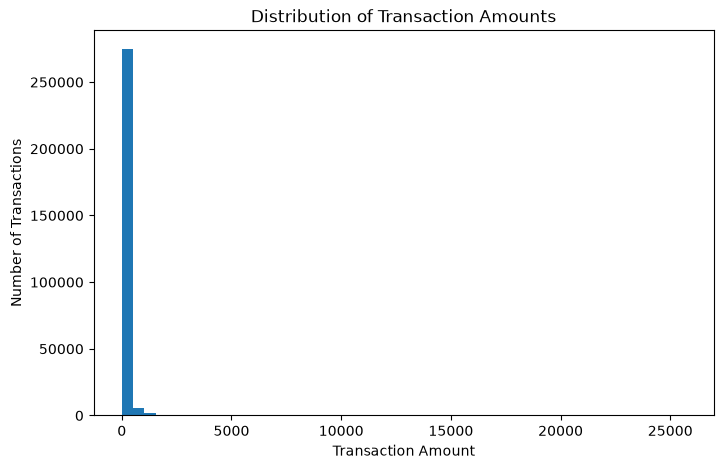

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_clean["Amount"], bins=50)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()

In [37]:
# Compare transaction amounts by class
print(df_clean.groupby("Class")["Amount"].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


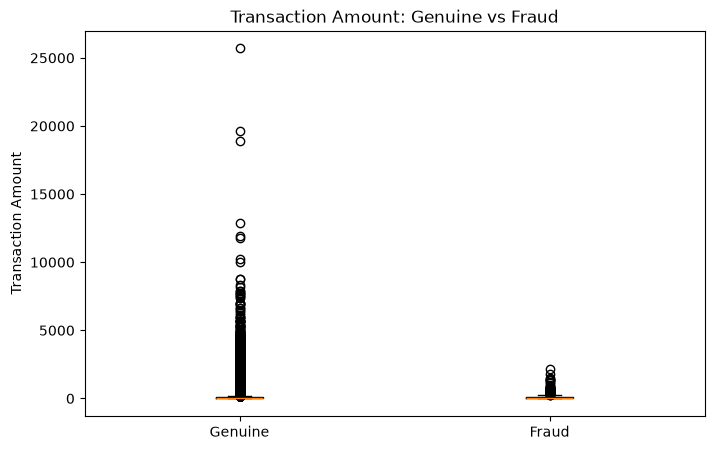

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df_clean[df_clean["Class"] == 0]["Amount"],
        df_clean[df_clean["Class"] == 1]["Amount"]
    ],
    tick_labels=["Genuine", "Fraud"]
)

plt.title("Transaction Amount: Genuine vs Fraud")
plt.ylabel("Transaction Amount")

plt.show()

In [39]:
# Separate input features (X) and target (y)

X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Input features shape: (283726, 30)
Target shape: (283726,)

Target distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nFraud transactions in training data:")
print(y_train.value_counts())

print("\nFraud transactions in testing data:")
print(y_test.value_counts())

Training data: (226980, 30)
Testing data: (56746, 30)

Fraud transactions in training data:
Class
0    226602
1       378
Name: count, dtype: int64

Fraud transactions in testing data:
Class
0    56651
1       95
Name: count, dtype: int64


In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create the ML pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [42]:
# Make predictions on unseen testing data
y_pred = model.predict(X_test)

print("First 20 actual values:")
print(y_test.head(20).values)

print("\nFirst 20 predicted values:")
print(y_pred[:20])

First 20 actual values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 predicted values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [43]:
from sklearn.metrics import confusion_matrix, classification_report

print("CONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred, digits=4))

CONFUSION MATRIX:
[[56641    10]
 [   40    55]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     56651
           1     0.8462    0.5789    0.6875        95

    accuracy                         0.9991     56746
   macro avg     0.9227    0.7894    0.8435     56746
weighted avg     0.9990    0.9991    0.9990     56746



In [44]:
# Get the probability of fraud for each transaction
y_prob = model.predict_proba(X_test)[:, 1]

print("First 10 fraud probabilities:")
print(y_prob[:10])

First 10 fraud probabilities:
[2.49737759e-04 2.04864321e-04 9.41796667e-05 1.44483188e-04
 1.15793577e-03 2.32723190e-04 1.06772110e-04 2.07092098e-04
 1.30031030e-04 1.58722658e-04]


In [45]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.9560466717268892


In [46]:
from sklearn.metrics import confusion_matrix, classification_report

# Change threshold from 50% to 20%
new_threshold = 0.20

# Create new predictions
y_pred_new = (y_prob >= new_threshold).astype(int)

print("CONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred_new))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_new, digits=4))

CONFUSION MATRIX:
[[56638    13]
 [   30    65]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0     0.9995    0.9998    0.9996     56651
           1     0.8333    0.6842    0.7514        95

    accuracy                         0.9992     56746
   macro avg     0.9164    0.8420    0.8755     56746
weighted avg     0.9992    0.9992    0.9992     56746



In [47]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

for threshold in thresholds:

    predictions = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")


Threshold: 0.1
Precision: 0.8333
Recall:    0.7368
F1 Score:  0.7821

Threshold: 0.2
Precision: 0.8333
Recall:    0.6842
F1 Score:  0.7514

Threshold: 0.3
Precision: 0.8356
Recall:    0.6421
F1 Score:  0.7262

Threshold: 0.4
Precision: 0.8529
Recall:    0.6105
F1 Score:  0.7117

Threshold: 0.5
Precision: 0.8462
Recall:    0.5789
F1 Score:  0.6875


In [50]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [51]:
# Predict transactions using Random Forest
rf_pred = rf_model.predict(X_test)

print("First 20 actual values:")
print(y_test.head(20).values)

print("\nFirst 20 Random Forest predictions:")
print(rf_pred[:20])

First 20 actual values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 Random Forest predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [52]:
from sklearn.metrics import confusion_matrix, classification_report

print("RANDOM FOREST CONFUSION MATRIX:")
print(confusion_matrix(y_test, rf_pred))

print("\nRANDOM FOREST CLASSIFICATION REPORT:")
print(classification_report(y_test, rf_pred, digits=4))

RANDOM FOREST CONFUSION MATRIX:
[[56647     4]
 [   26    69]]

RANDOM FOREST CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0     0.9995    0.9999    0.9997     56651
           1     0.9452    0.7263    0.8214        95

    accuracy                         0.9995     56746
   macro avg     0.9724    0.8631    0.9106     56746
weighted avg     0.9995    0.9995    0.9994     56746



In [53]:
from sklearn.metrics import roc_auc_score

rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest ROC-AUC:", rf_auc)

Random Forest ROC-AUC: 0.9391009960338881


In [54]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

for threshold in thresholds:

    predictions = (rf_prob >= threshold).astype(int)

    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")


Threshold: 0.1
Precision: 0.7156
Recall:    0.8211
F1 Score:  0.7647

Threshold: 0.2
Precision: 0.8652
Recall:    0.8105
F1 Score:  0.8370

Threshold: 0.3
Precision: 0.9125
Recall:    0.7684
F1 Score:  0.8343

Threshold: 0.4
Precision: 0.9333
Recall:    0.7368
F1 Score:  0.8235

Threshold: 0.5
Precision: 0.9452
Recall:    0.7263
F1 Score:  0.8214


In [55]:
rf_best_threshold = 0.20

rf_best_pred = (rf_prob >= rf_best_threshold).astype(int)

print("CONFUSION MATRIX:")
print(confusion_matrix(y_test, rf_best_pred))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, rf_best_pred, digits=4))

CONFUSION MATRIX:
[[56639    12]
 [   18    77]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9997     56651
           1     0.8652    0.8105    0.8370        95

    accuracy                         0.9995     56746
   macro avg     0.9324    0.9052    0.9183     56746
weighted avg     0.9995    0.9995    0.9995     56746



In [56]:
import matplotlib.pyplot as plt

top_10 = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10["Feature"],
    top_10["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features - Random Forest")

plt.gca().invert_yaxis()

plt.show()

NameError: name 'feature_importance' is not defined

In [57]:
from xgboost import XGBClassifier

# Calculate imbalance ratio
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=scale_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

# Train model
xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [58]:
xgb_pred = xgb_model.predict(X_test)

print("First 20 actual values:")
print(y_test.head(20).values)

print("\nFirst 20 XGBoost predictions:")
print(xgb_pred[:20])

First 20 actual values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 XGBoost predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [60]:
from sklearn.metrics import precision_score, recall_score, f1_score

xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:

    predictions = (xgb_prob >= threshold).astype(int)

    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("--------------------")

Threshold: 0.1
Precision: 0.0551
Recall:    0.8737
F1-score:  0.1037
--------------------
Threshold: 0.2
Precision: 0.1200
Recall:    0.8526
F1-score:  0.2104
--------------------
Threshold: 0.3
Precision: 0.1961
Recall:    0.8526
F1-score:  0.3189
--------------------
Threshold: 0.4
Precision: 0.2888
Recall:    0.8421
F1-score:  0.4301
--------------------
Threshold: 0.5
Precision: 0.3756
Recall:    0.8421
F1-score:  0.5195
--------------------


In [61]:
from sklearn.metrics import roc_auc_score

print("Logistic Regression:", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))

print("Random Forest:", roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]))

print("XGBoost:", roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]))

Logistic Regression: 0.9560466717268892
Random Forest: 0.9391009960338881
XGBoost: 0.9689243187048308


In [62]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train_new.shape)
print("Validation data:", X_val.shape)

print("\nTraining fraud transactions:")
print(y_train_new.value_counts())

print("\nValidation fraud transactions:")
print(y_val.value_counts())

Training data: (181584, 30)
Validation data: (45396, 30)

Training fraud transactions:
Class
0    181282
1       302
Name: count, dtype: int64

Validation fraud transactions:
Class
0    45320
1       76
Name: count, dtype: int64


In [63]:
# 1. Logistic Regression
model.fit(X_train_new, y_train_new)

# 2. Random Forest
rf_model.fit(X_train_new, y_train_new)

# 3. XGBoost
scale_weight = (
    (y_train_new == 0).sum() /
    (y_train_new == 1).sum()
)

xgb_model.set_params(scale_pos_weight=scale_weight)
xgb_model.fit(X_train_new, y_train_new)

print("All three models retrained successfully!")

All three models retrained successfully!


In [64]:
from sklearn.metrics import classification_report, confusion_matrix

# Logistic Regression
lr_val_pred = model.predict(X_val)

# Random Forest
rf_val_pred = rf_model.predict(X_val)

# XGBoost
xgb_val_pred = xgb_model.predict(X_val)


# Print results
models = {
    "Logistic Regression": lr_val_pred,
    "Random Forest": rf_val_pred,
    "XGBoost": xgb_val_pred
}

for name, predictions in models.items():

    print("\n==============================")
    print(name)
    print("==============================")

    print(confusion_matrix(y_val, predictions))

    print(classification_report(
        y_val,
        predictions,
        digits=4,
        zero_division=0
    ))


Logistic Regression
[[45315     5]
 [   24    52]]
              precision    recall  f1-score   support

           0     0.9995    0.9999    0.9997     45320
           1     0.9123    0.6842    0.7820        76

    accuracy                         0.9994     45396
   macro avg     0.9559    0.8421    0.8908     45396
weighted avg     0.9993    0.9994    0.9993     45396


Random Forest
[[45317     3]
 [   11    65]]
              precision    recall  f1-score   support

           0     0.9998    0.9999    0.9998     45320
           1     0.9559    0.8553    0.9028        76

    accuracy                         0.9997     45396
   macro avg     0.9778    0.9276    0.9513     45396
weighted avg     0.9997    0.9997    0.9997     45396


XGBoost
[[45248    72]
 [    9    67]]
              precision    recall  f1-score   support

           0     0.9998    0.9984    0.9991     45320
           1     0.4820    0.8816    0.6233        76

    accuracy                         0.9982 

In [65]:
from sklearn.metrics import roc_auc_score

lr_val_prob = model.predict_proba(X_val)[:, 1]
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]
xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]

print("Logistic Regression:", roc_auc_score(y_val, lr_val_prob))
print("Random Forest:", roc_auc_score(y_val, rf_val_prob))
print("XGBoost:", roc_auc_score(y_val, xgb_val_prob))

Logistic Regression: 0.9684616992613927
Random Forest: 0.9451257432526595
XGBoost: 0.9712181214289032


In [66]:
from sklearn.metrics import precision_score, recall_score, f1_score

rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:

    predictions = (rf_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, predictions)
    recall = recall_score(y_val, predictions)
    f1 = f1_score(y_val, predictions)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("--------------------")

Threshold: 0.1
Precision: 0.6768
Recall:    0.8816
F1-score:  0.7657
--------------------
Threshold: 0.2
Precision: 0.8462
Recall:    0.8684
F1-score:  0.8571
--------------------
Threshold: 0.3
Precision: 0.9028
Recall:    0.8553
F1-score:  0.8784
--------------------
Threshold: 0.4
Precision: 0.9559
Recall:    0.8553
F1-score:  0.9028
--------------------
Threshold: 0.5
Precision: 0.9559
Recall:    0.8553
F1-score:  0.9028
--------------------


In [67]:
from sklearn.metrics import confusion_matrix, classification_report

# Get fraud probabilities from Random Forest
rf_test_prob = rf_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
rf_test_pred = (rf_test_prob >= 0.40).astype(int)

print("TEST CONFUSION MATRIX:")
print(confusion_matrix(y_test, rf_test_pred))

print("\nTEST CLASSIFICATION REPORT:")
print(classification_report(y_test, rf_test_pred, digits=4))

TEST CONFUSION MATRIX:
[[56645     6]
 [   24    71]]

TEST CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9997     56651
           1     0.9221    0.7474    0.8256        95

    accuracy                         0.9995     56746
   macro avg     0.9608    0.8736    0.9127     56746
weighted avg     0.9994    0.9995    0.9994     56746



In [68]:
import joblib

joblib.dump(
    rf_model,
    "../models/fraud_detection_rf.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [69]:
import requests

url = "http://127.0.0.1:5000/predict"

# Take one transaction from test data
sample = X_test.iloc[[0]]

# Convert transaction into JSON
transaction_data = sample.iloc[0].to_dict()

# Send transaction to Flask API
response = requests.post(url, json=transaction_data)

print("Status Code:", response.status_code)
print("API Response:", response.json())

Status Code: 200
API Response: {'fraud_probability': 0.0, 'prediction': 0, 'result': 'Legitimate'}


In [70]:
# Find one actual fraud transaction
fraud_sample = X_test[y_test == 1].iloc[[0]]

# Convert it to JSON
fraud_data = fraud_sample.iloc[0].to_dict()

# Send it to API
response = requests.post(
    "http://127.0.0.1:5000/predict",
    json=fraud_data
)

print("Actual Class:", 1)
print("API Response:", response.json())

Actual Class: 1
API Response: {'fraud_probability': 0.92, 'prediction': 1, 'result': 'Fraud'}


In [72]:
fraud_sample = X_test[y_test == 1].iloc[0].to_dict()

import json
print(json.dumps(fraud_sample, indent=4))

{
    "Time": 74159.0,
    "V1": -1.54878809850026,
    "V2": 1.80869795041448,
    "V3": -0.953509033832342,
    "V4": 2.21308539346999,
    "V5": -2.01572779170327,
    "V6": -0.913456844516923,
    "V7": -2.35601298316433,
    "V8": 1.19716896702387,
    "V9": -1.67837405659509,
    "V10": -3.53865023182429,
    "V11": 3.1020899271543,
    "V12": -3.99337305447702,
    "V13": -1.93741062327519,
    "V14": -3.82289410599595,
    "V15": 0.830970110708369,
    "V16": -2.47535885382925,
    "V17": -5.21187516766885,
    "V18": -0.413871678166879,
    "V19": 0.933262164554872,
    "V20": 0.390785963777347,
    "V21": 0.855138263312025,
    "V22": 0.77474482148342,
    "V23": 0.0590371520063436,
    "V24": 0.343199807900813,
    "V25": -0.468937928609185,
    "V26": -0.278337986906642,
    "V27": 0.625922215184372,
    "V28": 0.395573378256676,
    "Amount": 76.94
}
